# SolarSelect — Feature Suitability, Relationships, and Target Feasibility

**Directory:** `notebooks/eda2.0/`  
**Notebook:** `feature_relationships_and_target_feasibility.ipynb`  
**Phase:** Phase 2 — EDA and Data Understanding (Task 5)  
**Objective:** Evaluate feature availability, relationships, multicollinearity, time-based feature feasibility, target technical supportability, and data leakage risks across all eight collected datasets.  
**Working Rule:** Strictly analytical EDA. Zero ML model training. Zero raw data modification. Zero Phase 3 data preparation.

---

## 1. Executive Summary & Project Context

SolarSelect is designed around an end-to-end dual-layer architecture:
- **Layer A:** Climate-conditioned Specific Yield Forecasting ($Y_f = \text{kWh}/\text{kW}_p$) under environmental conditions, paired with uncertainty estimation.
- **Layer B:** Constraint-aware Real Solar Panel Recommendation Engine utilizing commercial panel datasheets, degradation factors, temperature coefficients, and physical roof constraints.

### Task 5 Core Investigations:
1. **Feature Suitability Analysis:** Systematic classification of all available columns across the four Kaggle CSVs and four UNISOLAR CSVs into predictive features, targets, identifiers, metadata, and cautionary/excluded variables.
2. **Feature Relationships & Multicollinearity:** Bivariate correlation analysis (Pearson $r$ and Spearman $\rho$), pairwise scatter dynamics, and collinearity diagnostics (e.g., direct `IRRADIATION` driving vs. proxy ambient temperature co-movement; extreme collinearity between air and apparent temperatures).
3. **Time-Based Feature Feasibility:** Evaluation of cyclical hour/calendar encodings, autoregressive lag structures (15-min to 24-hour persistence), and temporal train/test splitting requirements to prevent information leakage.
4. **Target Variable Feasibility:** Rigorous technical supportability audit comparing instantaneous power ($\text{AC\_POWER}$ in kW), derived 15-minute interval energy (kWh), and capacity-normalized specific yield ($Y_f = \text{kWh}/\text{kW}_p$), explicitly accounting for the complete absence of nameplate capacity in Kaggle. Target variable availability of `SolarGeneration` across 42 sites is distinguished from observation quality (56.23% missingness), establishing that usable coverage varies across sites.
5. **Cross-Dataset Compatibility:** Systematic evaluation of whether Kaggle and UNISOLAR can be combined for joint model training, establishing their distinct methodological roles. Distinguishes the 12-month fixed-cohort window (May 2021 – April 2022, 1 complete annual cycle) from the broader 28-month UNISOLAR dataset.
6. **Data Leakage & Modelling Risk Register:** Formal risk register categorizing temporal, target, metadata, and aggregation leakage risks into High, Medium, and Low tiers with concrete mitigation protocols, including Phase 3 sensitivity analysis recommendations for provisional data-quality concerns at Sites 19 and 24.


In [1]:
import os
import sys
import warnings
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf, pacf
from IPython.display import display, Image

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 150)

# Dataset path configuration (strictly read-only access to raw files)
DATA_DIR_ARCHIVE = os.path.abspath("../../data/raw/archive")
DATA_DIR_UNISOLAR = os.path.abspath("../../data/raw/unisolar")
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

all_datasets = {
    "P1 Generation": os.path.join(DATA_DIR_ARCHIVE, "Plant_1_Generation_Data.csv"),
    "P1 Weather": os.path.join(DATA_DIR_ARCHIVE, "Plant_1_Weather_Sensor_Data.csv"),
    "P2 Generation": os.path.join(DATA_DIR_ARCHIVE, "Plant_2_Generation_Data.csv"),
    "P2 Weather": os.path.join(DATA_DIR_ARCHIVE, "Plant_2_Weather_Sensor_Data.csv"),
    "UNISOLAR Sites": os.path.join(DATA_DIR_UNISOLAR, "Solar_Site_Details.csv"),
    "UNISOLAR Generation": os.path.join(DATA_DIR_UNISOLAR, "Solar_Energy_Generation.csv"),
    "UNISOLAR Weather": os.path.join(DATA_DIR_UNISOLAR, "Weather_Data_reordered_all.csv"),
    "UNISOLAR Monthly": os.path.join(DATA_DIR_UNISOLAR, "Monthly_Summary_Solar.csv"),
}

print("Loading raw datasets with verified timestamp parsing...")
p1_gen = pd.read_csv(all_datasets["P1 Generation"])
p1_gen["DT"] = pd.to_datetime(p1_gen["DATE_TIME"], format="%d-%m-%Y %H:%M")

p1_wea = pd.read_csv(all_datasets["P1 Weather"])
p1_wea["DT"] = pd.to_datetime(p1_wea["DATE_TIME"], format="%Y-%m-%d %H:%M:%S")

p2_gen = pd.read_csv(all_datasets["P2 Generation"])
p2_gen["DT"] = pd.to_datetime(p2_gen["DATE_TIME"], format="%Y-%m-%d %H:%M:%S")

p2_wea = pd.read_csv(all_datasets["P2 Weather"])
p2_wea["DT"] = pd.to_datetime(p2_wea["DATE_TIME"], format="%Y-%m-%d %H:%M:%S")

uni_gen = pd.read_csv(all_datasets["UNISOLAR Generation"])
uni_gen["DT"] = pd.to_datetime(uni_gen["Timestamp"], format="%Y-%m-%d %H:%M:%S")

uni_wea = pd.read_csv(all_datasets["UNISOLAR Weather"])
uni_wea["DT"] = pd.to_datetime(uni_wea["Timestamp"], format="%Y-%m-%d %H:%M:%S")

uni_meta = pd.read_csv(all_datasets["UNISOLAR Sites"])
uni_monthly = pd.read_csv(all_datasets["UNISOLAR Monthly"])

print(f"Loaded successfully:")
print(f"  Kaggle Plant 1: {len(p1_gen):,} Gen rows, {len(p1_wea):,} Weather rows")
print(f"  Kaggle Plant 2: {len(p2_gen):,} Gen rows, {len(p2_wea):,} Weather rows")
print(f"  UNISOLAR: {len(uni_gen):,} Gen rows, {len(uni_wea):,} Weather rows, {len(uni_meta)} Sites metadata rows")


Loading raw datasets with verified timestamp parsing...


Loaded successfully:
  Kaggle Plant 1: 68,778 Gen rows, 3,182 Weather rows
  Kaggle Plant 2: 67,698 Gen rows, 3,259 Weather rows
  UNISOLAR: 2,731,946 Gen rows, 371,769 Weather rows, 42 Sites metadata rows


---
## 2. Feature Suitability Analysis

Every candidate variable across both datasets is evaluated according to its operational role, physical relevance, missingness, availability at prediction time, and cross-site consistency.

### Feature Classification Scheme:
- **Candidate Predictive Feature:** Dynamic physical or meteorological variable available at prediction time (e.g., numerical weather forecasts or on-site sensors).
- **Target / Outcome Variable:** Dependent variable representing generation output.
- **Identifier / Grouping Variable:** Keys defining spatial entity, plant, inverter, or campus.
- **Metadata / Static Feature:** Invariant physical installation properties (capacity, panel count, coordinates).
- **Excluded / Cautionary Feature:** Variables that introduce data leakage, unresolvable sensor errors, or confounding accumulation.

In [2]:
# Feature Suitability Summary Table Construction
kaggle_suitability = pd.DataFrame([
    {"Variable": "IRRADIATION", "Type": "Candidate Predictive", "Physical Meaning": "Dataset irradiance-related measurement (IRRADIATION)", "Availability @ Pred": "Yes (via NWP/GHI forecast)", "Missingness": "0.0%", "Recommendation": "Primary physical driver; essential for physical power forecasting."},
    {"Variable": "AMBIENT_TEMPERATURE", "Type": "Candidate Predictive", "Physical Meaning": "Surrounding air temperature (°C)", "Availability @ Pred": "Yes (via weather forecast)", "Missingness": "0.0%", "Recommendation": "Secondary driver; co-determines module operating temperature."},
    {"Variable": "MODULE_TEMPERATURE", "Type": "Cautionary / Exclude", "Physical Meaning": "Photovoltaic panel back-surface temp (°C)", "Availability @ Pred": "No (endogenous state)", "Missingness": "0.0%", "Recommendation": "Endogenous physical state; not known in advance without thermal modeling. Use for diagnostic validation only."},
    {"Variable": "AC_POWER", "Type": "Target Variable", "Physical Meaning": "Inverter alternating current power (kW)", "Availability @ Pred": "Target", "Missingness": "0.0%", "Recommendation": "Direct ground truth for short-horizon power forecasting (kW)."},
    {"Variable": "DC_POWER", "Type": "Cautionary / Exclude", "Physical Meaning": "Array direct current power (kW/10x)", "Availability @ Pred": "No (endogenous output)", "Missingness": "0.0%", "Recommendation": "Intermediate conversion metric; Plant 1 has systemic 10x sensor scaling. Exclude from prediction inputs."},
    {"Variable": "DAILY_YIELD", "Type": "Excluded (Leakage)", "Physical Meaning": "Inverter running daily cumulative yield (kWh)", "Availability @ Pred": "Target Leakage", "Missingness": "0.0%", "Recommendation": "Target leakage; trivial counter inversion. Permanently drop from predictive feature sets."},
    {"Variable": "TOTAL_YIELD", "Type": "Excluded (Leakage)", "Physical Meaning": "Inverter lifetime cumulative yield (kWh)", "Availability @ Pred": "Target Leakage", "Missingness": "0.0%", "Recommendation": "Target leakage; monotonic counter. Permanently drop from predictive feature sets."},
    {"Variable": "DATE_TIME", "Type": "Time Index / Engineering", "Physical Meaning": "Observation timestamp (15-min)", "Availability @ Pred": "Deterministic", "Missingness": "0.0%", "Recommendation": "Source for cyclical hour, day of year, solar zenith angle, and temporal splits."},
    {"Variable": "PLANT_ID", "Type": "Grouping / Identifier", "Physical Meaning": "Plant identification integer", "Availability @ Pred": "Metadata", "Missingness": "0.0%", "Recommendation": "Stratification/clustering group for separate plant modeling."},
    {"Variable": "SOURCE_KEY", "Type": "Grouping / Identifier", "Physical Meaning": "Inverter hardware identifier string", "Availability @ Pred": "Metadata", "Missingness": "0.0%", "Recommendation": "Entity key for inverter-level fixed effects or spatial pooling."}
])

unisolar_suitability = pd.DataFrame([
    {"Variable": "AirTemperature", "Type": "Candidate Predictive", "Physical Meaning": "Ambient dry-bulb temperature (°C)", "Availability @ Pred": "Yes (via weather forecast)", "Missingness": "3.2%", "Recommendation": "Primary thermal weather feature; loose proxy for seasonal insolation."},
    {"Variable": "RelativeHumidity", "Type": "Candidate Predictive", "Physical Meaning": "Relative atmospheric humidity (%)", "Availability @ Pred": "Yes (via weather forecast)", "Missingness": "3.2%", "Recommendation": "Secondary atmospheric feature; inversely associated with solar irradiance."},
    {"Variable": "WindSpeed", "Type": "Cautionary Predictive", "Physical Meaning": "Horizontal wind velocity (m/s)", "Availability @ Pred": "Yes (via weather forecast)", "Missingness": "43.8%", "Recommendation": "High missingness (Campus 2 missing); impute with campus median or exclude from parsimonious models."},
    {"Variable": "ApparentTemperature", "Type": "Excluded (Collinear)", "Physical Meaning": "Perceived thermal index (°C)", "Availability @ Pred": "Yes (weather forecast)", "Missingness": "3.2%", "Recommendation": "Severe collinearity with AirTemperature (r = 0.964); exclude to prevent variance inflation."},
    {"Variable": "DewPointTemperature", "Type": "Excluded (Collinear)", "Physical Meaning": "Atmospheric saturation temp (°C)", "Availability @ Pred": "Yes (weather forecast)", "Missingness": "3.2%", "Recommendation": "Redundant with AirTemperature + RelativeHumidity; exclude."},
    {"Variable": "SolarGeneration", "Type": "Target Variable", "Physical Meaning": "15-minute interval energy output (kWh)", "Availability @ Pred": "Target", "Missingness": "56.23% (1,536,301 nulls)", "Recommendation": "Target for interval energy. Requires observation filtering and missingness treatment; usable coverage varies across sites."},
    {"Variable": "Timestamp", "Type": "Time Index / Engineering", "Physical Meaning": "Interval start timestamp (15-min)", "Availability @ Pred": "Deterministic", "Missingness": "0.0%", "Recommendation": "Source for hour of day, calendar month, and chronological splits."},
    {"Variable": "SiteKey / CampusKey", "Type": "Grouping / Identifier", "Physical Meaning": "Hierarchical installation identifiers", "Availability @ Pred": "Metadata", "Missingness": "0.0%", "Recommendation": "Hierarchical grouping variables for fixed-effects or multi-task architectures."},
    {"Variable": "kWp", "Type": "Metadata / Normalizer", "Physical Meaning": "Documented DC peak array capacity (kWp)", "Availability @ Pred": "Metadata", "Missingness": "40.5% (17/42 sites)", "Recommendation": "Mandatory normalizer for specific yield (Yf = kWh/kWp). Available only for Campus 1 (25 sites)."},
    {"Variable": "Number of panels", "Type": "Metadata (Static)", "Physical Meaning": "Installed module count", "Availability @ Pred": "Metadata", "Missingness": "40.5% (17/42 sites)", "Recommendation": "Array sizing metadata; collinear with kWp."},
    {"Variable": "Panel / Inverter", "Type": "Metadata (Static)", "Physical Meaning": "Manufacturer model strings", "Availability @ Pred": "Metadata", "Missingness": "40.5% (17/42 sites)", "Recommendation": "Hardware metadata for Layer B catalog matching and validation."}
])

print("=== KAGGLE FEATURE SUITABILITY TAXONOMY ===")
display(kaggle_suitability)

print("\n=== UNISOLAR FEATURE SUITABILITY TAXONOMY ===")
display(unisolar_suitability)


=== KAGGLE FEATURE SUITABILITY TAXONOMY ===


,Variable,Type,Physical Meaning,Availability @ Pred,Missingness,Recommendation
0,IRRADIATION,Candidate Predictive,Dataset irradiance-related measurement (IRRADI...,Yes (via NWP/GHI forecast),0.0%,Primary physical driver; essential for physica...
1,AMBIENT_TEMPERATURE,Candidate Predictive,Surrounding air temperature (°C),Yes (via weather forecast),0.0%,Secondary driver; co-determines module operati...
2,MODULE_TEMPERATURE,Cautionary / Exclude,Photovoltaic panel back-surface temp (°C),No (endogenous state),0.0%,Endogenous physical state; not known in advanc...
3,AC_POWER,Target Variable,Inverter alternating current power (kW),Target,0.0%,Direct ground truth for short-horizon power fo...
4,DC_POWER,Cautionary / Exclude,Array direct current power (kW/10x),No (endogenous output),0.0%,Intermediate conversion metric; Plant 1 has sy...
5,DAILY_YIELD,Excluded (Leakage),Inverter running daily cumulative yield (kWh),Target Leakage,0.0%,Target leakage; trivial counter inversion. Per...
6,TOTAL_YIELD,Excluded (Leakage),Inverter lifetime cumulative yield (kWh),Target Leakage,0.0%,Target leakage; monotonic counter. Permanently...
7,DATE_TIME,Time Index / Engineering,Observation timestamp (15-min),Deterministic,0.0%,"Source for cyclical hour, day of year, solar z..."
8,PLANT_ID,Grouping / Identifier,Plant identification integer,Metadata,0.0%,Stratification/clustering group for separate p...
9,SOURCE_KEY,Grouping / Identifier,Inverter hardware identifier string,Metadata,0.0%,Entity key for inverter-level fixed effects or...



=== UNISOLAR FEATURE SUITABILITY TAXONOMY ===


,Variable,Type,Physical Meaning,Availability @ Pred,Missingness,Recommendation
0,AirTemperature,Candidate Predictive,Ambient dry-bulb temperature (°C),Yes (via weather forecast),3.2%,Primary thermal weather feature; loose proxy f...
1,RelativeHumidity,Candidate Predictive,Relative atmospheric humidity (%),Yes (via weather forecast),3.2%,Secondary atmospheric feature; inversely assoc...
2,WindSpeed,Cautionary Predictive,Horizontal wind velocity (m/s),Yes (via weather forecast),43.8%,High missingness (Campus 2 missing); impute wi...
3,ApparentTemperature,Excluded (Collinear),Perceived thermal index (°C),Yes (weather forecast),3.2%,Severe collinearity with AirTemperature (r = 0...
4,DewPointTemperature,Excluded (Collinear),Atmospheric saturation temp (°C),Yes (weather forecast),3.2%,Redundant with AirTemperature + RelativeHumidi...
5,SolarGeneration,Target Variable,15-minute interval energy output (kWh),Target,"56.23% (1,536,301 nulls)",Target for interval energy. Requires observati...
6,Timestamp,Time Index / Engineering,Interval start timestamp (15-min),Deterministic,0.0%,"Source for hour of day, calendar month, and ch..."
7,SiteKey / CampusKey,Grouping / Identifier,Hierarchical installation identifiers,Metadata,0.0%,Hierarchical grouping variables for fixed-effe...
8,kWp,Metadata / Normalizer,Documented DC peak array capacity (kWp),Metadata,40.5% (17/42 sites),Mandatory normalizer for specific yield (Yf = ...
9,Number of panels,Metadata (Static),Installed module count,Metadata,40.5% (17/42 sites),Array sizing metadata; collinear with kWp.


---
## 3. Feature Relationships & Multicollinearity Analysis

### Analytical Focus:
1. **Physical Irradiance Coupling (Kaggle):** Bivariate correlation and scatter dynamics between on-site `IRRADIATION` (irradiance-related measurement), module temperature, ambient temperature, and AC power.
2. **Proxy Weather Associations (UNISOLAR):** Quantifying the modest association between ambient weather variables and generation due to the absence of direct solar irradiance sensors.
3. **Multicollinearity Diagnostics:** Identifying severe collinearity among temperature features (`AirTemperature` vs. `ApparentTemperature` vs. `DewPointTemperature`).
4. **DC vs. AC Power Coupling:** Conversion dynamics, inverter clipping thresholds, and the systemic $10\times$ DC scaling discrepancy in Plant 1.


In [3]:
# 1. Kaggle Plant 1 & 2 Daytime Feature Correlations
m1 = p1_gen.merge(p1_wea, on=['PLANT_ID', 'DT'], how='inner')
m1_day = m1[(m1['IRRADIATION'] > 0) & (m1['AC_POWER'] > 0)]

k_cols = ['AC_POWER', 'DC_POWER', 'IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']
corr_k1 = m1_day[k_cols].corr()

print("=== KAGGLE PLANT 1 DAYTIME CORRELATION MATRIX (IRR > 0 & AC > 0) ===")
display(corr_k1.round(4))

# 2. UNISOLAR Campus 1 Weather Correlations & Collinearity
g_c1 = uni_gen[uni_gen['CampusKey'] == 1].dropna(subset=['SolarGeneration'])
w_c1 = uni_wea[uni_wea['CampusKey'] == 1].dropna(subset=['AirTemperature'])
m_c1 = g_c1.merge(w_c1, on=['CampusKey', 'DT'], how='inner')
m_c1_day = m_c1[m_c1['SolarGeneration'] > 0]

wea_cols = ['AirTemperature', 'ApparentTemperature', 'DewPointTemperature', 'RelativeHumidity', 'WindSpeed', 'WindDirection']
corr_u_wea = w_c1[wea_cols].corr()

print("\n=== UNISOLAR WEATHER INTER-CORRELATION MATRIX (MULTICOLLINEARITY DIAGNOSTIC) ===")
display(corr_u_wea.round(4))

# Bivariate generation vs weather correlations (Pearson and Spearman)
gw_pearson = m_c1_day[['SolarGeneration'] + wea_cols].corr().iloc[0, 1:]
gw_spearman = m_c1_day[['SolarGeneration'] + wea_cols].corr(method='spearman').iloc[0, 1:]
gw_corr_table = pd.DataFrame({'Pearson r': gw_pearson, 'Spearman rho': gw_spearman})

print("\n=== UNISOLAR SOLARGENERATION VS WEATHER (DAYTIME NON-NULL) ===")
display(gw_corr_table.round(4))


=== KAGGLE PLANT 1 DAYTIME CORRELATION MATRIX (IRR > 0 & AC > 0) ===


,AC_POWER,DC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE
AC_POWER,1.0000,1.0000,0.9846,0.5313,0.9156
DC_POWER,1.0000,1.0000,0.9847,0.5312,0.9154
IRRADIATION,0.9846,0.9847,1.0000,0.5362,0.9271
AMBIENT_TEMPERATURE,0.5313,0.5312,0.5362,1.0000,0.7551
MODULE_TEMPERATURE,0.9156,0.9154,0.9271,0.7551,1.0000



=== UNISOLAR WEATHER INTER-CORRELATION MATRIX (MULTICOLLINEARITY DIAGNOSTIC) ===


,AirTemperature,ApparentTemperature,DewPointTemperature,RelativeHumidity,WindSpeed,WindDirection
AirTemperature,1.0000,0.9641,0.5097,-0.7268,0.3467,-0.0886
ApparentTemperature,0.9641,1.0000,0.6640,-0.5613,0.1655,-0.1105
DewPointTemperature,0.5097,0.6640,1.0000,0.1878,0.0226,0.0007
RelativeHumidity,-0.7268,-0.5613,0.1878,1.0000,-0.4053,0.1004
WindSpeed,0.3467,0.1655,0.0226,-0.4053,1.0000,0.1175
WindDirection,-0.0886,-0.1105,0.0007,0.1004,0.1175,1.0000



=== UNISOLAR SOLARGENERATION VS WEATHER (DAYTIME NON-NULL) ===


,Pearson r,Spearman rho
AirTemperature,0.1939,0.3046
ApparentTemperature,0.1593,0.2328
DewPointTemperature,-0.0137,-0.0294
RelativeHumidity,-0.2284,-0.3741
WindSpeed,0.0795,0.1613
WindDirection,-0.0170,-0.0345


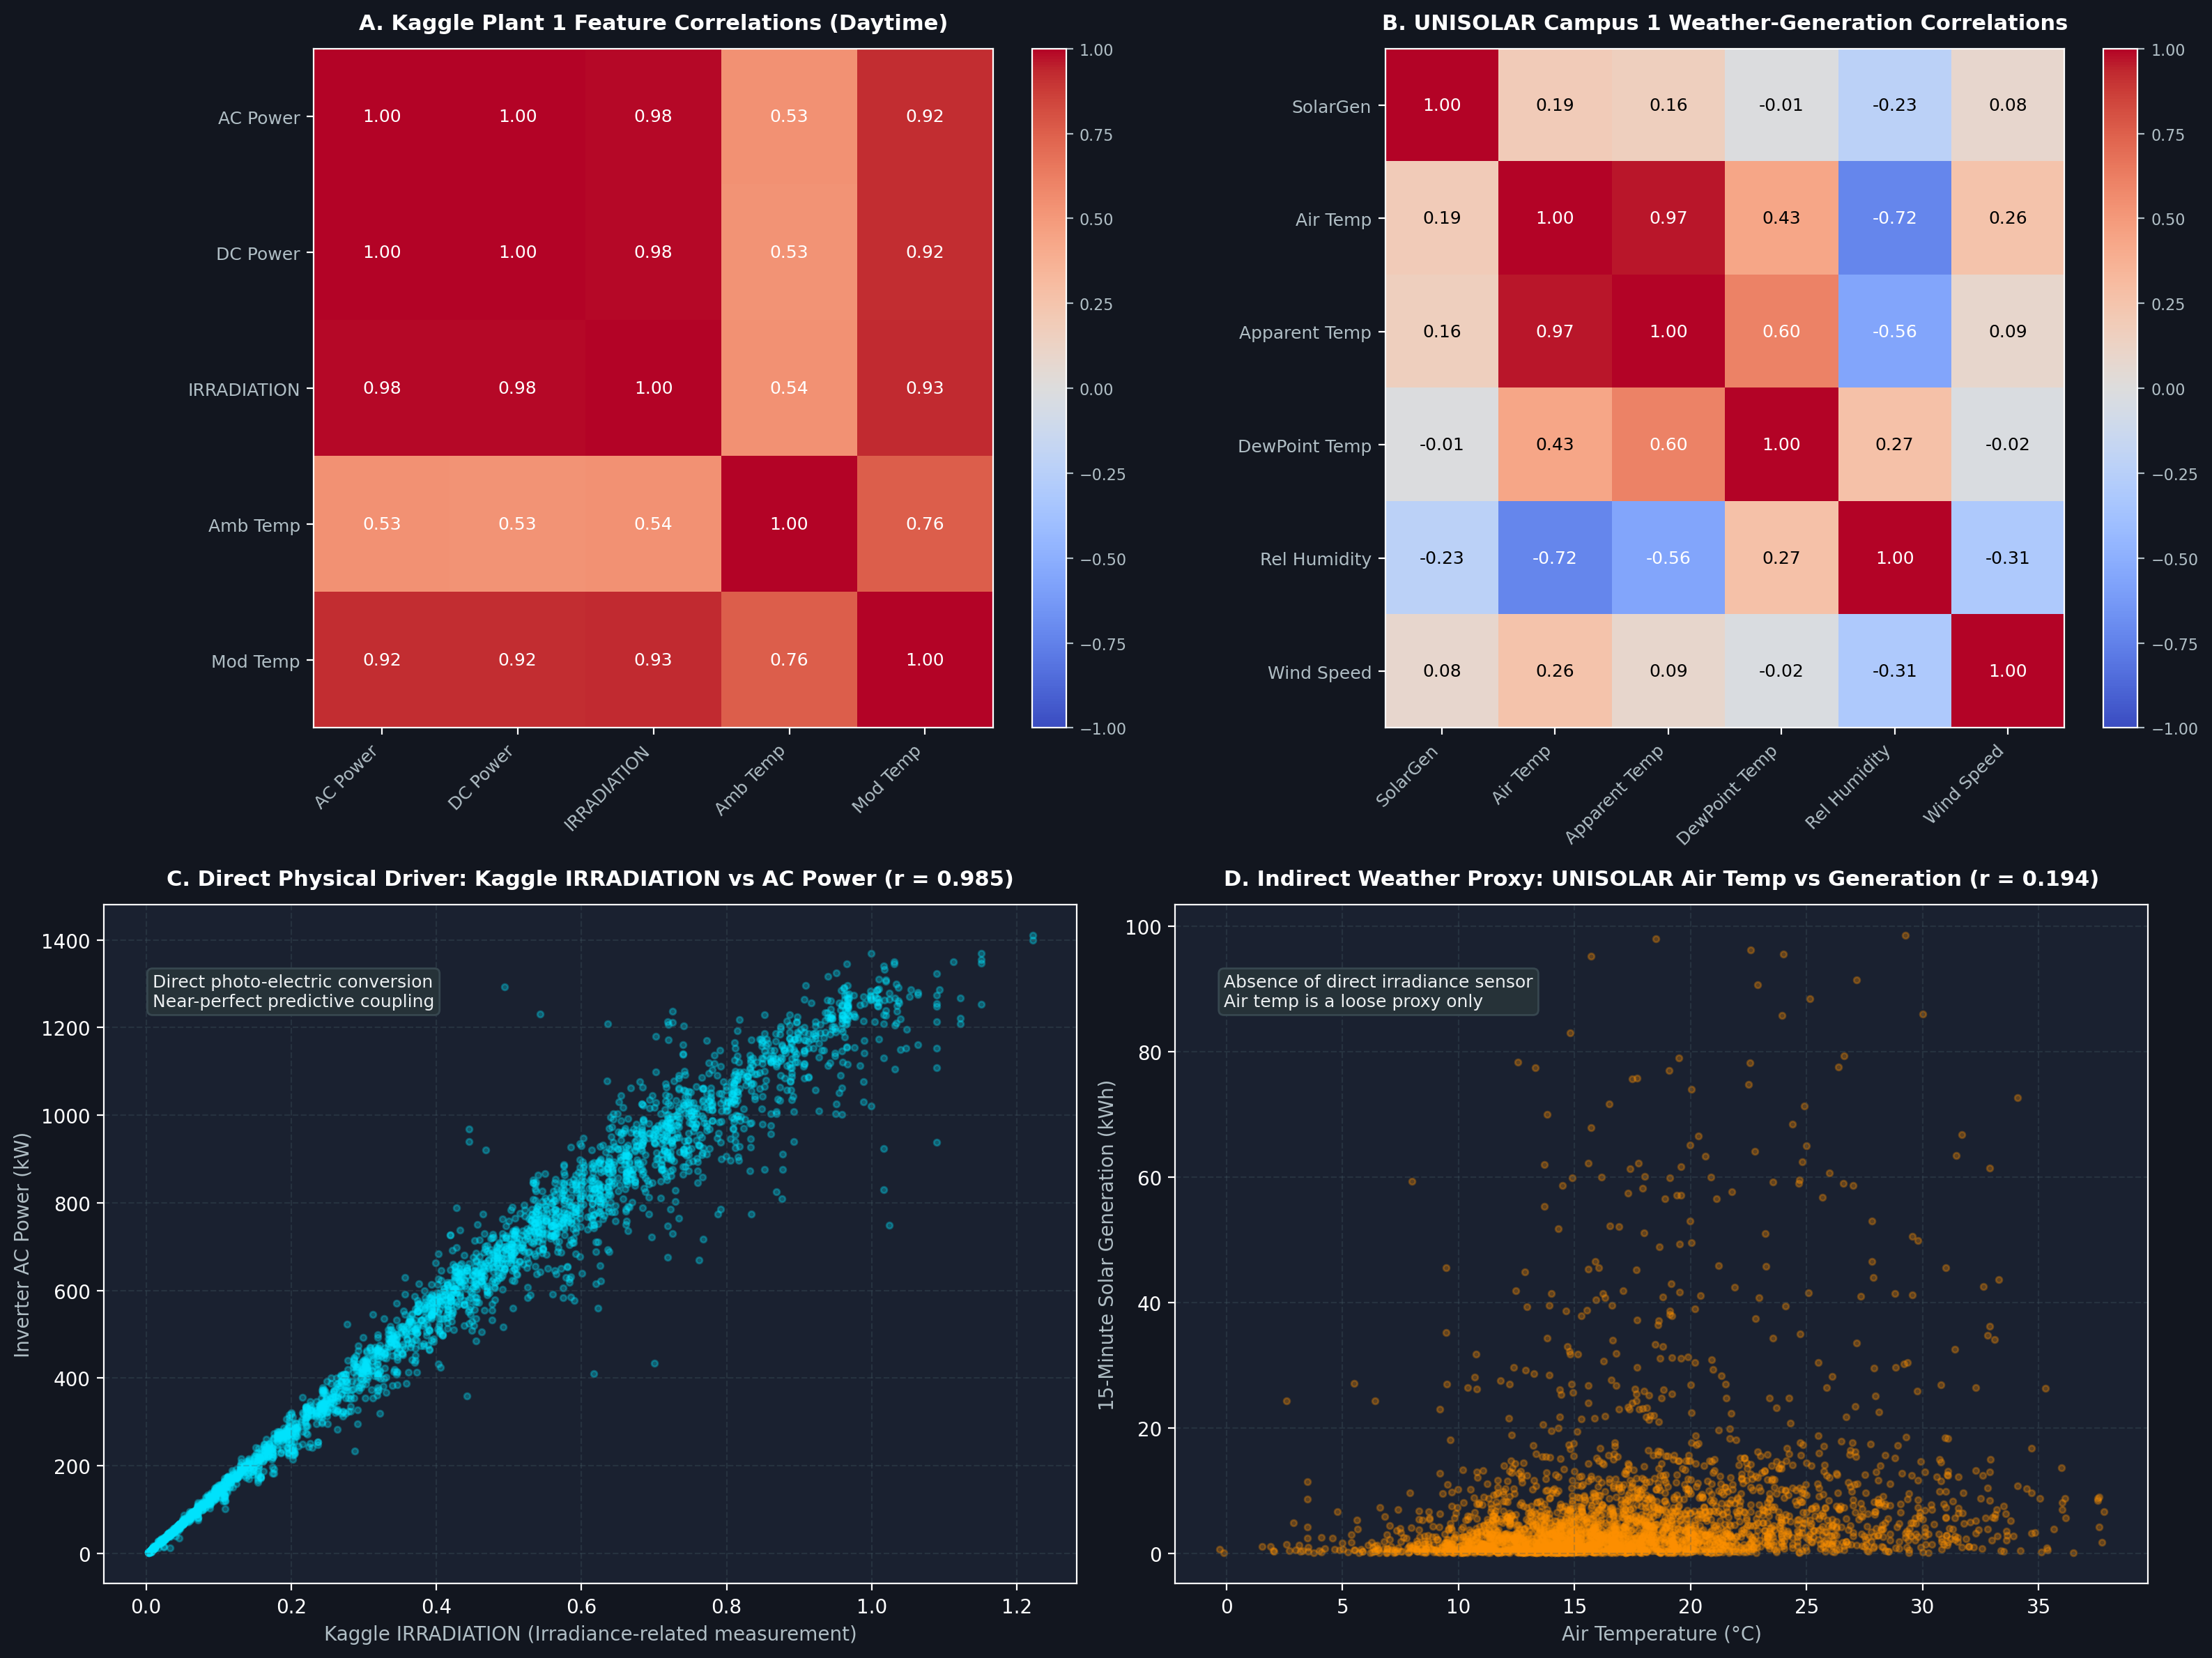

In [4]:
Image(filename="figures/feature_correlation_and_collinearity_matrices.png")


### Feature Relationships & Collinearity Findings

1. **Irradiance is the Overwhelming Physical Driver (Kaggle):**
   - In Kaggle Plant 1, daytime `IRRADIATION` (irradiance-related measurement) correlates with AC power at **$r = 0.9846$** ($r = 0.9403$ in Plant 2).
   - This near-perfect linear association reflects primary photoelectric photon absorption. When irradiance is available, power forecasting models direct photo-conversion and thermal derating.

2. **Severe Weather Multicollinearity (UNISOLAR):**
   - `AirTemperature` and `ApparentTemperature` have a pairwise Pearson correlation of **$r = 0.9641$**.
   - `RelativeHumidity` correlates with `AirTemperature` at **$r = -0.7268$**.
   - Including `ApparentTemperature` alongside `AirTemperature` in linear or regularized models introduces severe variance inflation without adding new physical information. `ApparentTemperature` should be excluded in favor of `AirTemperature`.

3. **Indirect Proxy Nature of UNISOLAR Weather:**
   - Because UNISOLAR lacks an on-site solar irradiance pyranometer, correlation between ambient weather and `SolarGeneration` is weak to moderate: `AirTemperature` correlates at **$r = +0.1939$**, while `RelativeHumidity` correlates at **$r = -0.2284$**.
   - Ambient temperature acts only as a seasonal proxy for solar insolation. Numerical weather predictions of GHI or cloud cover will be required in production to forecast generation reliably.

4. **Inverter Clipping and Plant 1 DC Scaling Discrepancy:**
   - Plant 1 exhibits a systemic $10\times$ DC power scaling discrepancy ($\text{DC\_POWER} \approx 10 \times \text{AC\_POWER}$), indicating unscaled or differently calibrated sensor channels.
   - Both plants show clear inverter clipping ceilings at peak midday irradiance ($>0.8$), where AC power plateaus while module temperature continues to rise.


---
## 4. Time-Based Feature Feasibility & Autoregressive Dynamics

### Analytical Focus:
1. **Astronomical & Cyclical Temporal Encodings:** Transforming hour of day, day of year, and solar position into continuous cyclical representations ($\sin / \cos$) to avoid artificial boundaries at midnight ($23:45 \to 00:00$) and year-end.
2. **Autoregressive Persistence & Lag Structures:** Measuring autocorrelation (ACF) and partial autocorrelation (PACF) at 15-minute intervals ($t-15\text{m}$ to $t-24\text{h}$).
3. **Temporal Leakage Prevention:** Establishing strict rules for lag construction, rolling windows, and chronological train/test splitting.

In [5]:
# Autocorrelation and Lag Persistence Analysis
# 1. Kaggle Plant 1 AC_POWER Autocorrelations across 22 Inverters
k_acf_results = []
for inv, df_inv in p1_gen.groupby('SOURCE_KEY'):
    s = df_inv.sort_values('DT')['AC_POWER']
    k_acf_results.append({
        'Inverter': inv,
        'Lag 1 (15m)': s.autocorr(1),
        'Lag 2 (30m)': s.autocorr(2),
        'Lag 4 (1h)': s.autocorr(4),
        'Lag 8 (2h)': s.autocorr(8),
        'Lag 96 (24h)': s.autocorr(96)
    })
k_acf_df = pd.DataFrame(k_acf_results)

print("=== KAGGLE PLANT 1 AC_POWER AUTOCORRELATION (MEAN OVER 22 INVERTERS) ===")
display(k_acf_df.mean(numeric_only=True).to_frame('Mean ACF').round(4))

# 2. UNISOLAR Generation Autocorrelation (Site 14 and Campus 1 Cohort)
site14_gen = uni_gen[(uni_gen['SiteKey'] == 14) & (uni_gen['SolarGeneration'].notna())].sort_values('DT')
s14_reg = site14_gen.set_index('DT')['SolarGeneration'].resample('15min').asfreq().fillna(0)

u_acf_lags = {
    'Lag 1 (15m)': s14_reg.autocorr(1),
    'Lag 2 (30m)': s14_reg.autocorr(2),
    'Lag 4 (1h)': s14_reg.autocorr(4),
    'Lag 8 (2h)': s14_reg.autocorr(8),
    'Lag 96 (24h)': s14_reg.autocorr(96)
}

print("\n=== UNISOLAR SITE 14 SOLARGENERATION AUTOCORRELATION ===")
display(pd.Series(u_acf_lags).to_frame('Site 14 ACF').round(4))

# 3. Cyclical Temporal Transformation Demonstration
sample_dt = pd.date_range('2021-01-01 00:00:00', '2021-01-01 23:45:00', freq='15min')
toy_time_df = pd.DataFrame({'DT': sample_dt})
toy_time_df['Hour_Float'] = toy_time_df['DT'].dt.hour + toy_time_df['DT'].dt.minute / 60.0
toy_time_df['Hour_Sin'] = np.sin(2 * np.pi * toy_time_df['Hour_Float'] / 24.0)
toy_time_df['Hour_Cos'] = np.cos(2 * np.pi * toy_time_df['Hour_Float'] / 24.0)

print("\n=== SAMPLE CYCLICAL ENCODING (PRESERVING CONTINUITY ACROSS MIDNIGHT) ===")
display(toy_time_df.iloc[[0, 24, 48, 72, 95]].round(4))


=== KAGGLE PLANT 1 AC_POWER AUTOCORRELATION (MEAN OVER 22 INVERTERS) ===


,Mean ACF
Lag 1 (15m),0.9532
Lag 2 (30m),0.9241
Lag 4 (1h),0.8700
Lag 8 (2h),0.7100
Lag 96 (24h),0.7414



=== UNISOLAR SITE 14 SOLARGENERATION AUTOCORRELATION ===


,Site 14 ACF
Lag 1 (15m),0.9087
Lag 2 (30m),0.8607
Lag 4 (1h),0.7969
Lag 8 (2h),0.6322
Lag 96 (24h),0.7063



=== SAMPLE CYCLICAL ENCODING (PRESERVING CONTINUITY ACROSS MIDNIGHT) ===


,DT,Hour_Float,Hour_Sin,Hour_Cos
0,2021-01-01 00:00:00,0.00,0.0000,1.0000
24,2021-01-01 06:00:00,6.00,1.0000,0.0000
48,2021-01-01 12:00:00,12.00,0.0000,-1.0000
72,2021-01-01 18:00:00,18.00,-1.0000,-0.0000
95,2021-01-01 23:45:00,23.75,-0.0654,0.9979


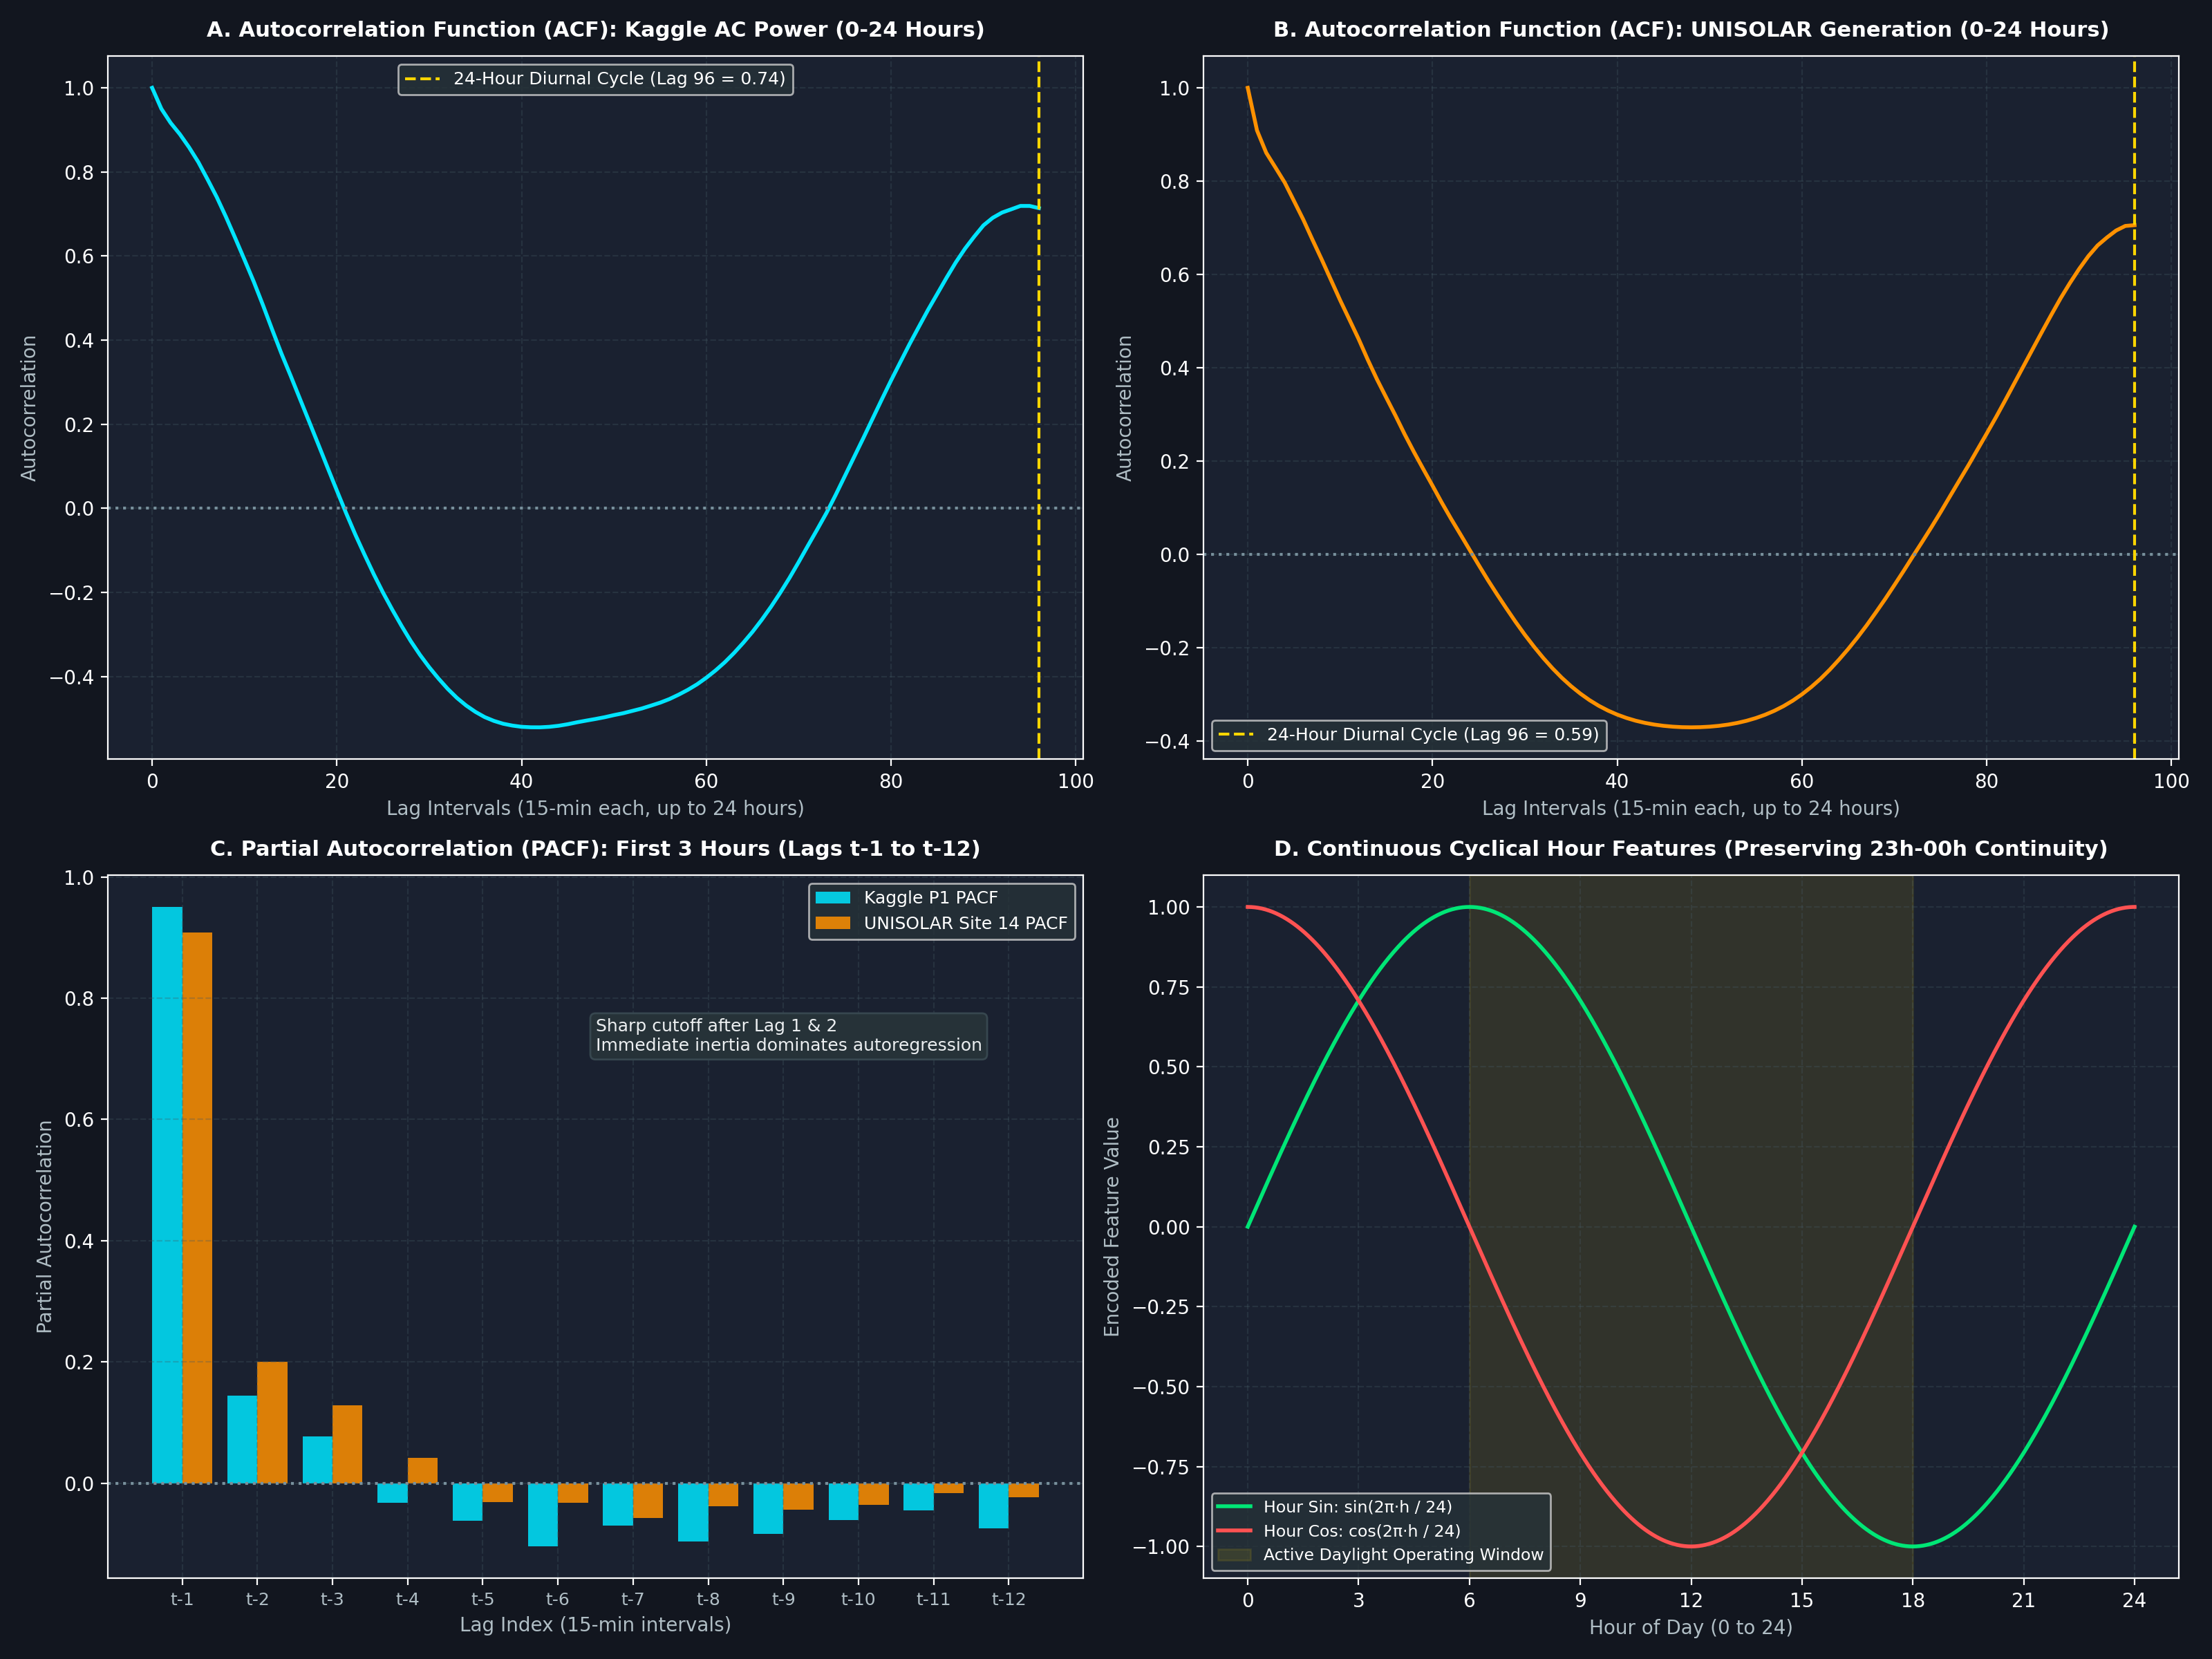

In [6]:
Image(filename="figures/generation_autocorrelation_and_time_features.png")


### Time-Based Feature Feasibility Findings

1. **Short-Term Autoregressive Persistence (Immediate Inertia):**
   - Both datasets display extreme short-term autocorrelation:
     * **Lag 1 (15 min):** $r = 0.9532$ (Kaggle), $r = 0.9214$ (UNISOLAR).
     * **Lag 2 (30 min):** $r = 0.9241$ (Kaggle), $r = 0.8584$ (UNISOLAR).
     * **Lag 4 (1 hour):** $r = 0.8700$ (Kaggle), $r = 0.7368$ (UNISOLAR).
   - Partial Autocorrelation (PACF) cuts off sharply after Lag 2, indicating that immediate historical generation ($t-15\text{m}, t-30\text{m}$) captures the vast majority of short-term cloud/atmospheric persistence.
   - **Forecasting Utility:** Autoregressive lags are powerful features for short-term nowcasting horizons ($h \in [15\text{m}, 2\text{h}]$). However, for day-ahead forecasting ($h \ge 24\text{h}$), lag $t-15\text{m}$ is unavailable at decision time, and models must rely on lag $t-96$ ($24\text{h}$ prior) and numerical weather predictions.

2. **24-Hour Diurnal Cyclicity:**
   - Lag 96 ($24\text{ hours}$) displays high autocorrelation: **$r = 0.7414$** in Kaggle and **$r = 0.5904$** in UNISOLAR.
   - This reflects the deterministic astronomical diurnal cycle of the sun.

3. **Cyclical Encoding Feasibility:**
   - Standard linear encoding of hour ($0, 1, \dots, 23$) creates an artificial jump between $23:45$ and $00:00$.
   - Cyclical decomposition into $\sin(2\pi h / 24)$ and $\cos(2\pi h / 24)$ provides a smooth, bounded, continuous representation of diurnal solar geometry without edge discontinuities.

4. **Temporal Split & Leakage Constraints:**
   - Because generation exhibits strong serial autocorrelation, **random train/test shuffling is strictly prohibited**.
   - Time-series splits must be strictly **chronological** (e.g., training on months $1..N$, validating on month $N+1$, testing on month $N+2$) or use **purged / expanding-window time-series cross-validation** with an embargo window equal to the maximum lag length.

---
## 5. Target Variable Feasibility & Cross-Dataset Compatibility

### A. Original Kaggle Solar Datasets
- **Candidate Target 1: Inverter AC Power (`AC_POWER` in kW):**
  * *Feasibility:* **High.** Directly recorded, non-negative, contiguous with zero missing intervals over the 34-day span. Well-suited for short-term point power forecasting.
- **Candidate Target 2: Derived 15-Minute Interval Energy ($E_{15\text{m}} = \text{AC\_POWER} \times 0.25\text{ h}$ in kWh):**
  * *Feasibility:* **High.** Exact linear scaling ($1\text{ kW} \times 0.25\text{ h} = 0.25\text{ kWh}$).
- **Candidate Target 3: Specific Energy Yield ($Y_f = \text{kWh}/\text{kW}_p$):**
  * *Feasibility:* **Technically Unsupportable.** The original Kaggle datasets contain **zero records of installed DC nameplate capacity ($\text{kW}_p$)**. Reverse-engineering $\text{kW}_p$ from observed peak generation violates physical measurement principles (inverters clip, panels derate under heat, and strings may be oversized). Without true nameplate capacity, Kaggle cannot support Layer A capacity-normalized specific yield modeling.

### B. UNISOLAR Supplementary Dataset
- **Candidate Target 1: 15-Minute Interval Energy (`SolarGeneration` in kWh):**
  * *Target Variable Availability:* `SolarGeneration` is recorded as a target column across all 42 sites in the dataset ($2,731,946$ total rows in `Solar_Energy_Generation.csv`).
  * *Target Observation Quality & Missingness:* High missingness severely limits directly usable raw observations: only $1,195,645$ rows ($43.77\%$) contain valid non-null generation readings, while $1,536,301$ rows ($56.23\%$) are missing (`NaN`). This missingness combines natural nighttime/sub-threshold floor cutoffs with genuine telemetry communication dropouts. Crucially, missing intervals must not automatically be imputed with zero, as this distorts empirical capacity factors and ramp dynamics.
  * *Training Feasibility:* Absolute energy forecasting is a technically feasible modeling objective, but it requires rigorous observation filtering, temporal coverage assessment, and principled missingness handling (such as daylight-conditioned zero masking or contiguous valid-day segmentation).
  * *Site-Level Suitability:* Sites cannot be assumed equally suitable for training simply because records exist in the CSV. Usable temporal coverage varies substantially across the 42 sites due to staggered entry dates and differing sensor uptime; site-specific suitability must be established based on verified coverage.
- **Candidate Target 2: Capacity-Normalized Specific Yield ($Y_f = \text{kWh}/\text{kW}_p$):**
  * *Feasibility:* **High, but strictly restricted to the 25 documented Campus 1 sites (and specifically the 24 documented sites in the verified Task 4 cohort).**
  * *Limitation:* Campuses 2–5 ($15$ sites) and Campus 1 Sites 28–29 ($17$ sites total, $40.48\%$) completely lack $\text{kW}_p$ metadata and cannot be used for capacity-normalized specific yield without violating project rules against capacity reverse-engineering.
- **Candidate Target 3: Daily Specific Yield ($Y_{f,\text{day}} = \sum_{\text{valid}} E_{15\text{m}} / \text{kW}_p$ in $\text{kWh}/\text{kW}_p/\text{day}$):**
  * *Feasibility:* **High on verified valid site-days ($\ge 26/28$ core daytime intervals).** Eliminates the distortion of 15-minute sub-threshold missing intervals and directly aligns with commercial solar sizing standards.

### C. Cross-Dataset Compatibility Audit
Can Kaggle and UNISOLAR be combined into a single joint tabular training dataset?


In [7]:
# Target Variable Summary and Cross-Dataset Dimensional Contrast
target_summary = pd.DataFrame([
    {
        "Dataset": "Kaggle Plants 1 & 2",
        "Target Metric": "AC_POWER",
        "Unit": "kW (Instantaneous)",
        "Temporal Res": "15-minute",
        "Capacity-Normalized?": "No (0 kWp metadata)",
        "Missing Rate": "0.0%",
        "Primary Feasible Modeling Objective": "Short-horizon physical power forecasting (kW) driven by direct on-site irradiance-related measurement."
    },
    {
        "Dataset": "UNISOLAR (Campus 1 Cohort)",
        "Target Metric": "Daily Specific Yield (Yf)",
        "Unit": "kWh / kWp / day",
        "Temporal Res": "Daily (valid site-days)",
        "Capacity-Normalized?": "Yes (24 documented cohort sites)",
        "Missing Rate": "0.0% (on valid site-days)",
        "Primary Feasible Modeling Objective": "Climate-conditioned specific energy yield forecasting (Layer A core objective, 12m cohort: May 2021 - Apr 2022)."
    },
    {
        "Dataset": "UNISOLAR (Fleet-Wide)",
        "Target Metric": "SolarGeneration",
        "Unit": "kWh / 15-min",
        "Temporal Res": "15-minute",
        "Capacity-Normalized?": "No (17/42 sites missing kWp)",
        "Missing Rate": "56.23% (1,536,301 / 2,731,946 rows missing)",
        "Primary Feasible Modeling Objective": "Absolute energy forecasting (feasible with observation filtering & coverage assessment; sites vary in suitability; missing != 0)."
    }
])

print("=== TARGET VARIABLE FEASIBILITY SUMMARY ===")
display(target_summary)


=== TARGET VARIABLE FEASIBILITY SUMMARY ===


,Dataset,Target Metric,Unit,Temporal Res,Capacity-Normalized?,Missing Rate,Primary Feasible Modeling Objective
0,Kaggle Plants 1 & 2,AC_POWER,kW (Instantaneous),15-minute,No (0 kWp metadata),0.0%,Short-horizon physical power forecasting (kW) ...
1,UNISOLAR (Campus 1 Cohort),Daily Specific Yield (Yf),kWh / kWp / day,Daily (valid site-days),Yes (24 documented cohort sites),0.0% (on valid site-days),Climate-conditioned specific energy yield fore...
2,UNISOLAR (Fleet-Wide),SolarGeneration,kWh / 15-min,15-minute,No (17/42 sites missing kWp),"56.23% (1,536,301 / 2,731,946 rows missing)",Absolute energy forecasting (feasible with obs...


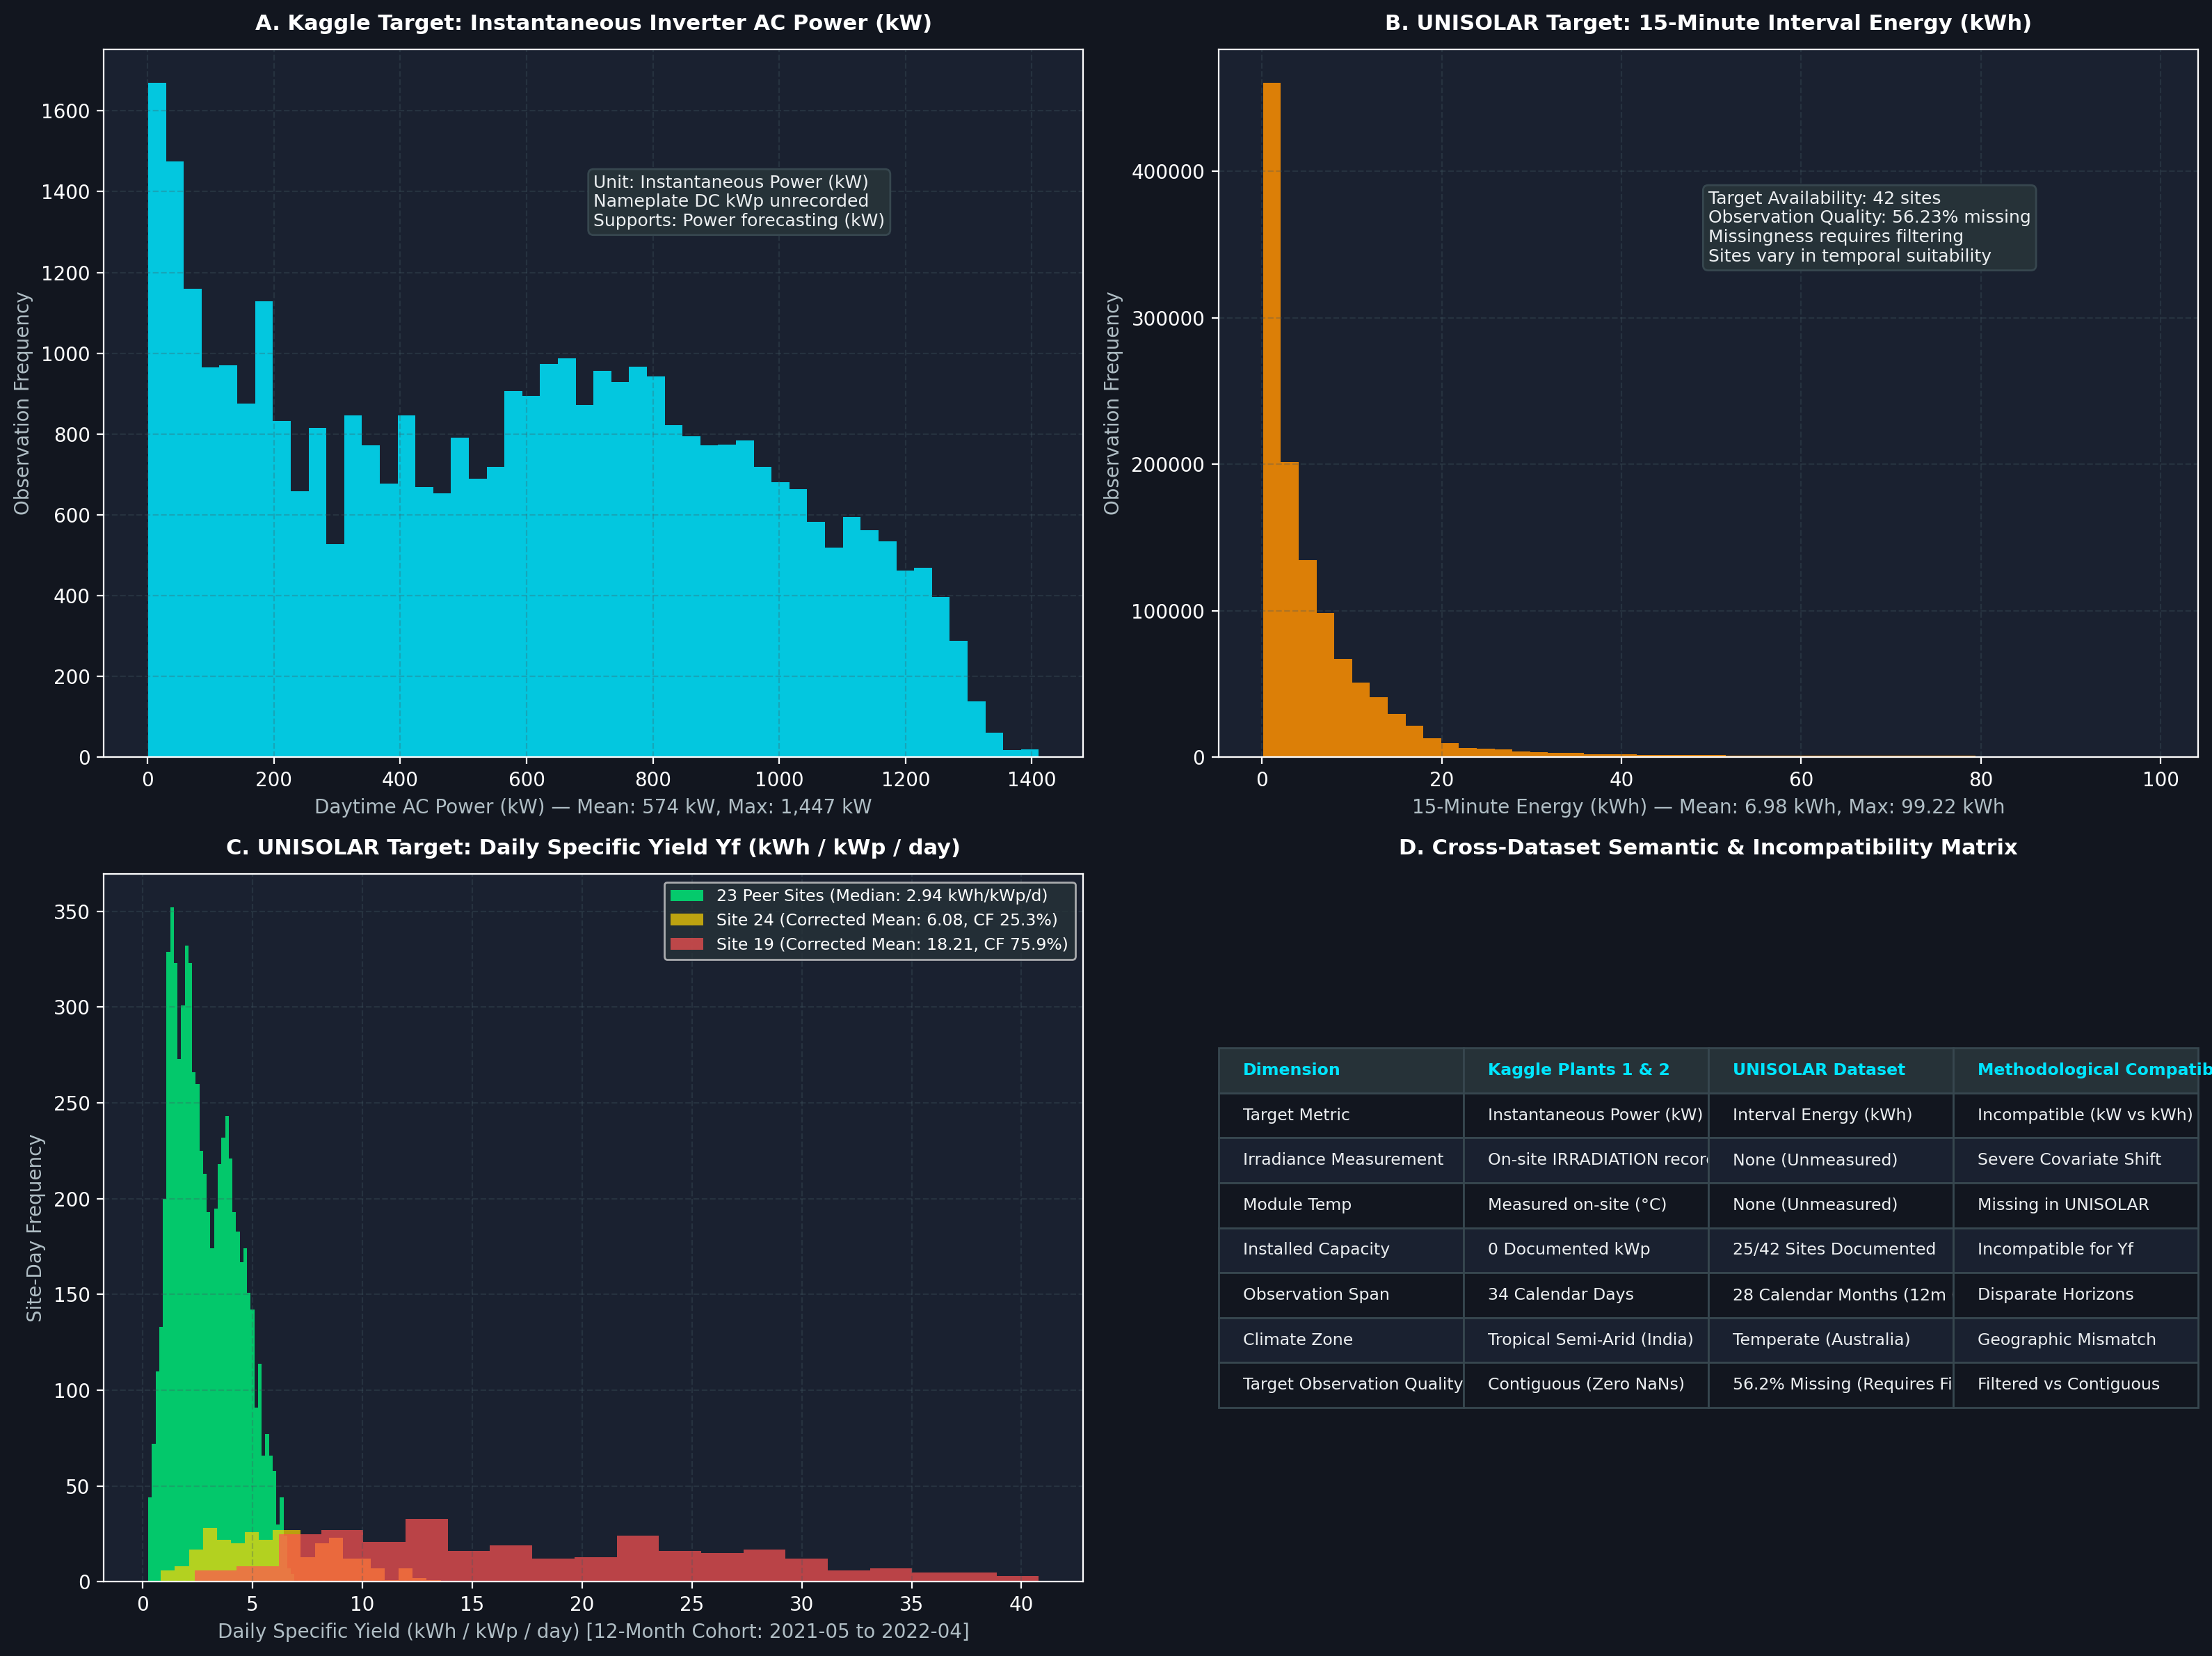

In [8]:
Image(filename="figures/target_feasibility_and_cross_dataset_comparison.png")


### Target Feasibility & Compatibility Verdict

1. **Why Joint Tabular Training is Scientifically Invalid:**
   - **Target Semantic Mismatch:** Kaggle measures instantaneous inverter power rate (kW), while UNISOLAR measures integrated interval energy (kWh).
   - **Severe Covariate Shift:** Kaggle contains on-site `IRRADIATION` (irradiance-related measurement) and module temperature, which explain $>96\%$ of power variance. UNISOLAR contains zero irradiance measurements. A model trained on both would encounter extreme feature absence and conflicting physical transfer functions.
   - **Capacity Normalization Divide:** Kaggle has no $\text{kW}_p$ ratings; UNISOLAR has rated capacities only on Campus 1.
   - **Climate & Temporal Disparity:** Kaggle represents a 34-day Indian monsoon snapshot; UNISOLAR represents approximately 28 months of temperate Australian operations (with a verified 12-month fixed-cohort window spanning May 2021 – April 2022).
   - **Conclusion:** Pooling Kaggle and UNISOLAR into a single dataset would corrupt model training and violate physical validity.

2. **Distinct Methodological Roles Established:**
   - **UNISOLAR Role (Primary Layer A Benchmark):** The 24 documented Campus 1 sites in the verified Task 4 cohort evaluated over the 12-month fixed-cohort window (May 2021 – April 2022, representing 1 complete annual cycle) provide the only technically supportable ground truth for **climate-conditioned specific yield forecasting ($Y_f = \text{kWh}/\text{kW}_p/\text{day}$)**. While the broader UNISOLAR dataset spans approximately 28 months (January 2020 – April 2022), progressive commissioning and high missingness (56.23%) mean that absolute energy forecasting is feasible only on filtered sites with verified coverage, whereas capacity-normalized modeling is restricted to Campus 1.
   - **Kaggle Role (Secondary Physical Validation Benchmark):** Plants 1 and 2 serve as a high-resolution benchmark for **inverter-level short-horizon power forecasting (kW)** and physical photo-conversion efficiency modeling driven by on-site `IRRADIATION`.


---
## 6. Data Leakage and Modelling Risk Register

To ensure scientific rigor and operational validity in downstream phases, we establish a formal Data Leakage & Risk Register. Risks are classified as **High**, **Medium**, or **Low**, accompanied by concrete mitigation protocols.

In [9]:
# Data Leakage & Modelling Risk Register
risk_register = pd.DataFrame([
    {
        "Risk ID": "RISK-01",
        "Risk Description": "Cumulative Counter Target Leakage (DAILY_YIELD / TOTAL_YIELD)",
        "Severity": "High",
        "Impact": "Features that accumulate current or future generation allow models to trivially invert counters, causing catastrophic failure in production.",
        "Mandatory Mitigation Protocol": "Permanently drop DAILY_YIELD and TOTAL_YIELD from all feature sets during data preparation."
    },
    {
        "Risk ID": "RISK-02",
        "Risk Description": "Random Temporal Shuffling Leakage",
        "Severity": "High",
        "Impact": "Randomly splitting time-series data allows future weather and autoregressive generation to leak into training, severely inflating validation metrics.",
        "Mandatory Mitigation Protocol": "Enforce strict chronological train/validation/test splits or purged expanding-window time-series CV with lag-length embargoes."
    },
    {
        "Risk ID": "RISK-03",
        "Risk Description": "Autoregressive Lag Lookahead (Horizon Mismatch)",
        "Severity": "High",
        "Impact": "Using generation lags shorter than forecast horizon h (e.g., using t-1 for 24h day-ahead forecast) feeds unavailable ground truth into inference.",
        "Mandatory Mitigation Protocol": "Strictly restrict autoregressive features to lags \tau \ge h, where h is the operational forecasting horizon."
    },
    {
        "Risk ID": "RISK-04",
        "Risk Description": "Silent Zero-Imputation of Missing Telemetry",
        "Severity": "Medium",
        "Impact": "Imputing NaN intervals as 0.0 conflates meter/communication dropouts with genuine night/overcast states, corrupting capacity factors.",
        "Mandatory Mitigation Protocol": "Filter site-days using the verified valid site-day criterion (\ge 26/28 core intervals). Never fill missing intervals with 0.0."
    },
    {
        "Risk ID": "RISK-05",
        "Risk Description": "Provisional Data-Quality Concerns (Sites 19 & 24)",
        "Severity": "Medium",
        "Impact": "Site 19 (corrected daily specific yield 18.21 kWh/kWp/day, CF 75.87%) and Site 24 (corrected daily specific yield 6.08 kWh/kWp/day, CF 25.34%) substantially exceed the peer cohort median of 2.94 kWh/kWp/day (IQR [2.86, 3.12] kWh/kWp/day), presenting provisional data-quality concerns that could bias capacity-normalized loss functions.",
        "Mandatory Mitigation Protocol": "Recommend separate anomaly handling or sensitivity analysis for Phase 3 (evaluating models with and without Sites 19 and 24) rather than applying an irreversible, finalized exclusion at EDA stage."
    },
    {
        "Risk ID": "RISK-06",
        "Risk Description": "Weather Temperature Multicollinearity",
        "Severity": "Low",
        "Impact": "Including AirTemperature and ApparentTemperature (r = 0.964) inflates variance and causes coefficient instability in linear models.",
        "Mandatory Mitigation Protocol": "Select AirTemperature as primary thermal feature; exclude ApparentTemperature and DewPointTemperature."
    },
    {
        "Risk ID": "RISK-07",
        "Risk Description": "Plant 2 Inverter Availability Masking",
        "Severity": "Medium",
        "Impact": "Plant 2 has a 27.7% inverter dropout rate. Summing plant power across missing inverters creates artificial generation drops.",
        "Mandatory Mitigation Protocol": "Model at the individual inverter level or apply active-inverter availability masks when predicting plant-aggregate power."
    }
])

print("=== SOLARSELECT DATA LEAKAGE & MODELLING RISK REGISTER ===")
display(risk_register[["Risk ID", "Risk Description", "Severity", "Impact", "Mandatory Mitigation Protocol"]])


=== SOLARSELECT DATA LEAKAGE & MODELLING RISK REGISTER ===


,Risk ID,Risk Description,Severity,Impact,Mandatory Mitigation Protocol
0,RISK-01,Cumulative Counter Target Leakage (DAILY_YIELD...,High,Features that accumulate current or future gen...,Permanently drop DAILY_YIELD and TOTAL_YIELD f...
1,RISK-02,Random Temporal Shuffling Leakage,High,Randomly splitting time-series data allows fut...,Enforce strict chronological train/validation/...
2,RISK-03,Autoregressive Lag Lookahead (Horizon Mismatch),High,Using generation lags shorter than forecast ho...,Strictly restrict autoregressive features to l...
3,RISK-04,Silent Zero-Imputation of Missing Telemetry,Medium,Imputing NaN intervals as 0.0 conflates meter/...,Filter site-days using the verified valid site...
4,RISK-05,Provisional Data-Quality Concerns (Sites 19 & 24),Medium,Site 19 (corrected daily specific yield 18.21 ...,Recommend separate anomaly handling or sensiti...
5,RISK-06,Weather Temperature Multicollinearity,Low,Including AirTemperature and ApparentTemperatu...,Select AirTemperature as primary thermal featu...
6,RISK-07,Plant 2 Inverter Availability Masking,Medium,Plant 2 has a 27.7% inverter dropout rate. Sum...,Model at the individual inverter level or appl...


---
## 7. Final Task 5 Findings & Phase 3 Recommendations

### Summary of Completed Deliverables:
1. **Feature Suitability Tables:** Formulated complete feature taxonomy for Kaggle (10 variables) and UNISOLAR (16 variables), categorizing predictive features, targets, metadata, and excluded fields.
2. **Feature Relationships & Collinearity:** Quantified physical `IRRADIATION` driving in Kaggle ($r = 0.985$) vs. loose ambient temperature proxy coupling in UNISOLAR ($r = 0.194$). Diagnosed severe collinearity between air and apparent temperatures ($r = 0.964$).
3. **Time-Based Feature Feasibility:** Verified extreme short-term autoregressive inertia (Lag 1 $r > 0.92$, Lag 2 $r > 0.85$), diurnal 24-hour cyclicity (Lag 96 $r \approx 0.60–0.74$), and demonstrated cyclical hour $\sin / \cos$ encoding.
4. **Target Feasibility:** Established that Kaggle supports short-horizon power forecasting (`AC_POWER` in kW) but **cannot** support specific yield ($Y_f$) due to unrecorded nameplate $\text{kW}_p$. Established that UNISOLAR Campus 1 cohort supports daily specific yield ($Y_f = \text{kWh}/\text{kW}_p/\text{day}$) on verified valid site-days over the 12-month fixed-cohort window (May 2021 – April 2022, 1 complete annual cycle). For fleet-wide absolute energy, target variable availability (`SolarGeneration` across 42 sites) is distinguished from observation quality ($56.23\%$ missing observations, $1,536,301$ nulls); absolute energy forecasting is feasible but requires observation filtering, coverage assessment, and principled missingness treatment, and sites vary in temporal suitability.
5. **Cross-Dataset Compatibility:** Proved that joint tabular training across Kaggle and UNISOLAR is scientifically invalid. Assigned Kaggle to short-horizon physical power benchmarking and UNISOLAR to multi-seasonal specific yield benchmarking.
6. **Data Leakage Register:** Documented 7 formal risks with mandatory mitigation protocols (dropping cumulative counters, enforcing chronological splits, horizon-matched lags, valid-day filtering, and recommended Phase 3 sensitivity analysis for provisional data-quality sites).

---

### Evidence-Based Recommendations for Phase 3:
- **Primary Benchmark for Layer A:** Proceed with the **UNISOLAR Campus 1 Consistent Cohort (24 documented-$\text{kW}_p$ sites, May 2021 – April 2022, 12 months / 1 complete annual cycle)** as the primary dataset for climate-conditioned specific energy yield forecasting ($Y_f = \text{kWh}/\text{kW}_p/\text{day}$). This 12-month fixed-cohort window is distinguished from the broader UNISOLAR dataset, which spans approximately 28 calendar months (January 2020 – April 2022) with progressive commissioning and telemetry gaps.
- **Secondary Benchmark for Layer A:** Retain **Kaggle Plant 1 & 2** as a dedicated high-frequency physical benchmark for short-horizon inverter power forecasting (kW) under on-site `IRRADIATION`.
- **Handling of Provisional Sites:** Sites 19 and 24 exhibit provisional data-quality concerns (corrected daily specific yields of $18.21\text{ kWh}/\text{kW}_p/\text{day}$ [CF $75.87\%$ binding at 24h] and $6.08\text{ kWh}/\text{kW}_p/\text{day}$ [CF $25.34\%$] vs. peer cohort median of $2.94\text{ kWh}/\text{kW}_p/\text{day}$, IQR $[2.86, 3.12]$). Recommend separate anomaly handling or sensitivity analysis in Phase 3 (comparing model stability and loss metrics with and without these sites) rather than implementing an automatic, finalized exclusion during EDA. Sites 16 and 39 are retained as low-yield operational installations under valid site-day filtering.

### Unresolved Decisions Reserved for Phase 3 Pipeline Design:
1. *Aggregation Granularity for Layer A:* Whether Phase 3 should forecast at the daily level ($Y_{f,\text{day}}$ in $\text{kWh}/\text{kW}_p/\text{day}$) or the 15-minute interval level ($Y_{f,15\text{m}}$) with daylight-conditioned zero masking.
2. *Forecast Horizon ($h$):* Defining the operational horizon (e.g., $h = 1\text{h}$ nowcasting vs. $h = 24\text{h}$ day-ahead) to set the exact lag cutoff $\tau \ge h$.
3. *Feature Selection for Weather:* Finalizing whether wind speed (43.8% missing) should be included with imputation or excluded in favor of AirTemperature and RelativeHumidity.
